Today we're making a message bank to practice web development using Dash. Let's import the necessary packages first. We'll also use SQLite to store the messages in a database.

In [2]:
import os
import sqlite3
import random
import pandas as pd
import plotly.express as px
from dash import Dash, html, dash_table, dcc, callback, Output, Input, State
from textwrap import dedent #for formatting

# Defining Functions

### `get_message_db()`
This function checks to see if a database called 'messages_db.sqlite' exists, and, if not, creates a new one. It then returns the connection as a variable called `message_db`.

In [4]:
def get_message_db():
    """
    checks if there is already a messages database; if not then it creates one.
    returns connection to the database as variable named message_db
    
    """
    global message_db
    if os.path.isfile('messages_db.sqlite'):
        return sqlite3.connect('messages_db.sqlite')
    else:
        message_db = sqlite3.connect("messages_db.sqlite", check_same_thread=False)
        cursor = message_db.cursor()
        cursor.execute('''CREATE TABLE IF NOT EXISTS messages (
                   handle TEXT,
                   message TEXT);''')
        return message_db

### `insert_message(handle, message)`
This function takes a user's handle and message that they enter into the message bank and inserts it into our database.

In [6]:
def insert_message(handle, message):
    """
    inserts a message and handle into the messages database
    returns none
    """
    with get_message_db() as conn:
        cursor = conn.cursor()
        cmd = f"""INSERT INTO messages (handle, message)
        VALUES ('{handle}', '{message}');"""
        cursor.execute(cmd)
        conn.commit()

### `random_messages(n)`
This function returns `n` random messages from the message bank.

In [8]:
def random_messages(n):
    with get_message_db() as conn:
        cursor = conn.cursor()
        cursor.execute('SELECT MAX(rowid) FROM messages')
        length = cursor.fetchone()
        mylist = [x for x in range(1, length[0] + 1)]
        randoms = tuple(random.sample(mylist, n))
        messages = []
        for x in randoms:
            cursor.execute(f'SELECT handle, message FROM messages WHERE rowid = {x};')
            messages.append(cursor.fetchone())
        return messages

# Making the App

## Initializing the App and Variables

In [10]:
# Initialize the app
app = Dash()

markdown_text1 = '''
# Message Bank

## Submit a new message to the bank here:
'''
markdown_text2 = '''


## View:

'''
bank = []

## App Layout

In [12]:
app.layout = html.Div(children=[
    dcc.Markdown(children=markdown_text1, style={'color':'darkblue'}),
    dcc.Textarea(
        id='message-input',
        placeholder='Message',
        style={'width': '100%', 'height': 100},
    ),
    dcc.Textarea(
        id='name-input',
        placeholder='Name/Handle',
        style={'width': '100%', 'height': 50},
    ),
    html.Button('Submit', id='submit-button', n_clicks=0),
    html.Div(id='message-output', style={'whiteSpace': 'pre-line'}),
    dcc.Markdown(children=markdown_text2, style={'color':'green'}),
    dcc.Markdown(id='random-messages', dangerously_allow_html = True),
    html.Button('Update', id='update-button', n_clicks=0)
], style={'backgroundColor':'#F5F5F5', 'fontFamily':'sans-serif'})

Note that the app layout is comprised of `html` elements and `dcc` (dash core component) elements. We use `dcc` to render Markdown text.

## Callback Functions
These functions are how we update components based on user interaction. The `@callback` is a special wrapper for the function that specifies which components to consider and which to alter.

### `submit()`
The `submit()` function is what allows users' messages and handles to be added to the bank. The `@callback` wrapper tells the function that the `Input` is the number of clicks on the Submit button (this is what makes it update when the user clicks the Submit button). The `State` elements are similar to arguments for the function - this is what enables it to extract the user's message and handle from the `textarea` elements where they type them in. Finally, the `Output` element is what the function is updating: here it is printing "Message received!"

In [15]:
@callback(
    Output('message-output', 'children'),
    Input('submit-button', 'n_clicks'),
    State('message-input', 'value'),
    State('name-input', 'value')
)
def submit(n_clicks, message, handle):
    if n_clicks > 0:
        insert_message(handle, message)
        return 'Message received!'

### `view()`
The `view()` function is what displays and updates the quotes underneath. The `Input` is the same as in `submit()`, so that the quotes are updated upon the user clicking the Update button. The `Output` is changing the children of the `dcc` component with id 'random-messages', which to the user looks like the quotes being updated.

In [17]:
@callback(
    Output('random-messages', 'children'),
    Input('update-button', 'n_clicks')
)
def view(n_clicks):
    messages = random_messages(5)
    display = ''''''
    rainbow = ['#15317E', '#0000A5', '#0000CD', '#045F5F', '#006A4E']
    for x in range(5):
        display += f'''
        <span style="color:{rainbow[x]}" children="{messages[x][1]}" />  
        
        - *{messages[x][0]}*   
        
        '''
    return dedent(display)

## Running the App
Finally, we are ready to run our app!

In [19]:
if __name__ == '__main__':
    app.run(debug=True)

# Results
Here is what it should look like when a user submits a message:

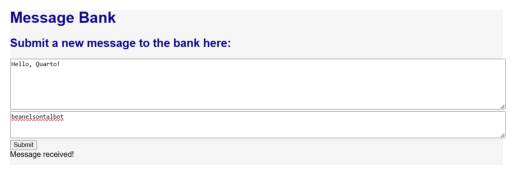

In [21]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
img = mpimg.imread('message_submission.png')
imgplot = plt.imshow(img)
plt.axis('off')
plt.show()

And here is what it should look like when a user updates the message display:

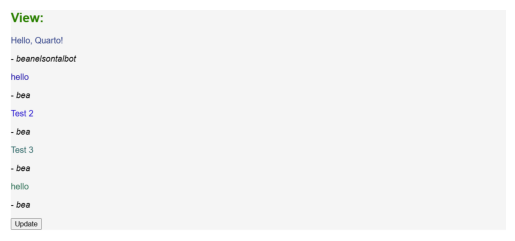

In [23]:
img = mpimg.imread('messages_display.png')
imgplot = plt.imshow(img)
plt.axis('off')
plt.show()